# Livrable 2: Image denoising
**Projet Leyenda — TouNum**

TouNum scans at speed, and some scans come out noisy. Before captioning (Livrable 3), those images have to be cleaned.

This notebook continues **Livrable 1**: its saved classifier decides which images are photographs, and a **convolutional autoencoder** then cleans them.

## The problem to solve first
The delivered dataset contains **148 noisy images and no clean versions**. A denoiser is trained on pairs (noisy → clean), so there is nothing to learn from as it stands.

Our answer, in three steps:
1. **Measure** the noise actually present in TouNum's images.
2. **Recreate** it on the clean photographs of Livrable 1, which gives as many exact pairs as we want.
3. **Apply** the trained model to the real noisy images, and check the result both visually and by measurement.

| Section | Content |
|---|---|
| 1 | The chain: Livrable 1 filters the noisy batch |
| 2 | Measuring the real noise |
| 3 | Building training pairs |
| 4 | Architecture of the convolutional autoencoder |
| 5 | Training |
| 6 | Evaluation on known pairs (PSNR) |
| 7 | Application to TouNum's real images |
| 8 | The autoencoder as a feature extractor (comparison with Livrable 1) |
| 9 | Analysis and improvements |

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential

# The delivery has been reorganised more than once, so the root is searched
# rather than hard-coded (per-class folders, a flat folder, or an extra level
# left behind when the archives are unzipped in place).
ROOT = Path(r"C:\my\CESI\A5\Data Science\Data")

def find_dir(*parts):
    for folder in [ROOT, *sorted(p for p in ROOT.iterdir() if p.is_dir())]:
        if (folder.joinpath(*parts)).is_dir():
            return folder.joinpath(*parts)
    return None

DATA_DIR = (find_dir("Dataset Livrable 1 - Photo", "Photo") or find_dir("Dataset Livrable 1")).parent
if DATA_DIR.name.startswith("Dataset Livrable 1 - "):      # found the inner class folder
    DATA_DIR = DATA_DIR.parent
NOISY_DIR = find_dir("Dataset Livrable 2", "Dataset")
print("data:", DATA_DIR, "| noisy:", NOISY_DIR)

# The Livrable 1 images now live in one flat folder; the class is in the file
# name (photo_*, painting_*, schematics_*, text_*, anything else = sketch).
# The per-class folders of the first delivery are still handled, if present.
FLAT_DIR = DATA_DIR / "Dataset Livrable 1"
PREFIXES = {"photo": "Photo", "painting": "Painting",
            "schematics": "Schematics", "text": "Text"}

def source_of(name):
    low = name.lower()
    for prefix, src in PREFIXES.items():
        if low.startswith(prefix):
            return src
    return "Sketch"

IMAGE_EXT = {".jpg", ".jpeg", ".png"}     # 800 of the sketches are PNG

def list_images(source):
    folder = DATA_DIR / f"Dataset Livrable 1 - {source}" / source
    if folder.is_dir():                                   # original layout
        return sorted(p for p in folder.iterdir() if p.suffix.lower() in IMAGE_EXT)
    return sorted(p for p in FLAT_DIR.iterdir()           # flat layout
                  if p.suffix.lower() in IMAGE_EXT and source_of(p.name) == source)

IMG_SIZE = 128        # working size of the denoiser
CLS_SIZE = 256        # input size of the Livrable 1 classifier (padded square)
BATCH_SIZE = 32
MAX_EPOCHS = 20
PATIENCE = 3
N_CLEAN = 6000        # clean photographs used to build the pairs
SEED = 42

tf.keras.utils.set_random_seed(SEED)
print("TensorFlow", tf.__version__)
print(len(list(NOISY_DIR.glob("*.jpg"))), "noisy images |", len(list_images("Photo")), "clean photos")

data: C:\my\CESI\A5\Data Science\Data\OneDrive_1_10-13-2026 | noisy: C:\my\CESI\A5\Data Science\Data\OneDrive_1_10-13-2026\Dataset Livrable 2\Dataset
TensorFlow 2.21.0


148 noisy images | 9993 clean photos


## 1. The chain: Livrable 1 filters the batch
The deliverables form a pipeline. Before cleaning anything we run **the classifier of Livrable 1** (`Jupyter_notebook_p1_complete_1.ipynb`: a PyTorch CNN, images padded to 256×256, trained in two steps, test accuracy 0.9743 / F1 0.9478) over TouNum's 148 noisy images.

The model is reloaded exactly as Livrable 1 defines it — same class, same pre-processing (`resize_with_pad` to 256, pixels scaled to [0, 1]), same 0.5 decision threshold on the sigmoid — from its saved weights `models/photo_classifier_best.pth`.

Two things come out of it: the images to clean, and a first measurement — *does noise disturb the classifier?* It was trained on clean images, so this is a genuine test of its robustness.

Livrable 1 classifier loaded from models\photo_classifier_best.pth | device cpu


kept as photographs: 102 / 148


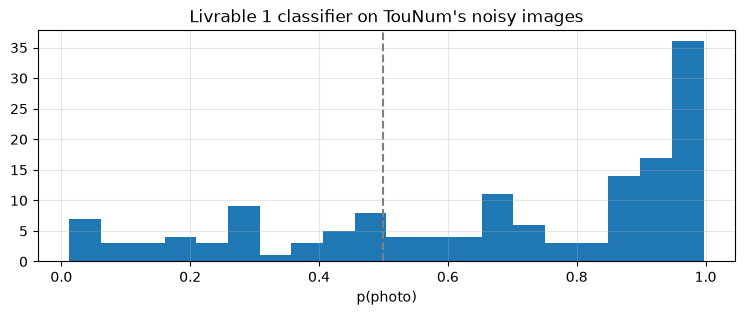

In [2]:
import torch
import torch.nn as nn

# The classifier of Livrable 1, unchanged (Jupyter_notebook_p1_complete_1.ipynb, cell "CNN")
class PhotoClassifier(nn.Module):

    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(inplace=True),
            nn.Conv2d(32, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(inplace=True),
            nn.Conv2d(128, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Conv2d(128, 256, 3, padding=1), nn.BatchNorm2d(256), nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d((1, 1)))
        self.classifier = nn.Sequential(nn.Flatten(), nn.Dropout(0.3), nn.Linear(256, 1))

    def forward(self, x):
        return self.classifier(self.features(x))

WEIGHTS = Path("models/photo_classifier_best.pth")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
classifier = PhotoClassifier().to(device)
classifier.load_state_dict(torch.load(WEIGHTS, map_location=device))
classifier.eval()
THRESHOLD = 0.5                        # the decision rule of Livrable 1: sigmoid >= 0.5
print("Livrable 1 classifier loaded from", WEIGHTS, "| device", device)

noisy_paths = sorted(NOISY_DIR.glob("*.jpg"))

def read_image(path, size):
    # Livrable 1 pre-processing: pad to a square of `size`, keep proportions, pixels in [0, 1]
    img = tf.io.decode_image(tf.io.read_file(str(path)), channels=3, expand_animations=False)
    return tf.image.resize_with_pad(img, size, size) / 255.0

def p_photo_of(images01):
    # images01: array (n, H, W, 3) in [0, 1]  ->  probability of "photo" per image
    x = torch.from_numpy(np.asarray(images01, dtype="float32")).permute(0, 3, 1, 2).to(device)
    with torch.no_grad():
        return torch.sigmoid(classifier(x)).cpu().numpy().ravel()

real_cls = np.stack([read_image(p, CLS_SIZE).numpy() for p in noisy_paths])
p_photo = p_photo_of(real_cls)

kept = p_photo >= THRESHOLD
print(f"kept as photographs: {kept.sum()} / {len(noisy_paths)}")
plt.figure(figsize=(9, 3))
plt.hist(p_photo, bins=20)
plt.axvline(THRESHOLD, color="grey", linestyle="--")
plt.title("Livrable 1 classifier on TouNum's noisy images"); plt.xlabel("p(photo)"); plt.grid(alpha=0.3);

*Comment on the figure: how many images pass, and are the rejected ones genuinely not photographs, or photographs that the noise disturbed? The classifier never saw noisy images during training, so a drop here is expected and is itself an argument for denoising **before** the rest of the pipeline.*

## 2. Measuring the real noise
We cannot copy noise we have not looked at. For each image we estimate the **standard deviation of the noise** by comparing it with a median-filtered version of itself: the filter removes the grain, and what is left is mostly noise.

The robust estimator is `sigma ≈ 1.4826 × median(|image − median_filter(image)|)` — the 1.4826 converts a median absolute deviation into a standard deviation for Gaussian noise.

estimated sigma on TouNum's images: mean 0.007, min 0.000, max 0.036  (pixels in [0, 1])


same estimator on clean photographs: mean 0.006


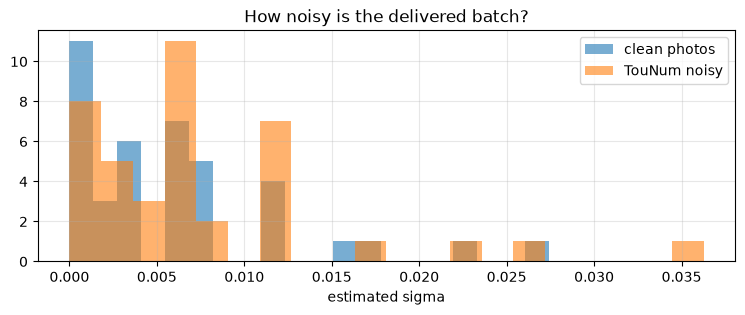

In [3]:
from scipy.ndimage import median_filter

# img: float array in [0, 1]; returns the estimated noise sigma, in the same scale
def estimate_sigma(img):
    smooth = median_filter(img, size=(3, 3, 1))
    return 1.4826 * np.median(np.abs(img - smooth))

sample = [read_image(p, IMG_SIZE).numpy() for p in noisy_paths[:40]]
sigmas = np.array([estimate_sigma(im) for im in sample])
print(f"estimated sigma on TouNum's images: mean {sigmas.mean():.3f}, "
      f"min {sigmas.min():.3f}, max {sigmas.max():.3f}  (pixels in [0, 1])")

clean_paths = list_images("Photo")
clean_sample = [read_image(p, IMG_SIZE).numpy() for p in clean_paths[:40]]
clean_sigmas = np.array([estimate_sigma(im) for im in clean_sample])
print(f"same estimator on clean photographs: mean {clean_sigmas.mean():.3f}")

plt.figure(figsize=(9, 3))
plt.hist(clean_sigmas, bins=20, alpha=0.6, label="clean photos")
plt.hist(sigmas, bins=20, alpha=0.6, label="TouNum noisy")
plt.legend(); plt.xlabel("estimated sigma"); plt.title("How noisy is the delivered batch?"); plt.grid(alpha=0.3);

The gap between the two histograms is what we have to reproduce. Note the limit of the method: the estimator also reacts to fine **texture**, so a detailed clean photograph gets a non-zero value. We therefore use the difference between the two distributions, not the absolute number.

In [4]:
# Noise levels used for training: a range around what was measured, so the model
# does not learn one single level by heart.
NOISE_MIN = float(max(0.02, clean_sigmas.mean()))
NOISE_MAX = float(max(0.10, sigmas.mean() * 1.5))
print(f"training noise sigma drawn in [{NOISE_MIN:.3f}, {NOISE_MAX:.3f}]")

training noise sigma drawn in [0.020, 0.100]


## 3. Building the training pairs
Each pair is: **a clean photograph of Livrable 1** on one side, **the same photograph with noise we added** on the other. The clean image is the target, so supervision is free and exact.

Two choices worth defending:
- **A random noise level per image**, drawn in the interval above, instead of one fixed level. A model trained on a single level generalises badly to any other.
- **Noise drawn afresh at every epoch**, so the model never sees the same noisy image twice. This acts as data augmentation and is why this architecture over-fits so little.

In [5]:
paths_used = [str(p) for p in clean_paths[:N_CLEAN]]
n_val = int(0.15 * len(paths_used))
train_paths, val_paths = paths_used[n_val:], paths_used[:n_val]
print(len(train_paths), "training photos |", len(val_paths), "validation photos")

def load_clean(path):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE)) / 255.0
    return img

def add_noise(clean):
    sigma = tf.random.uniform([], NOISE_MIN, NOISE_MAX)
    noisy = clean + tf.random.normal(tf.shape(clean), stddev=sigma)
    return tf.clip_by_value(noisy, 0.0, 1.0), clean      # (input, target)

def make_pairs(paths, training):
    ds = tf.data.Dataset.from_tensor_slices(paths)
    ds = ds.map(load_clean, num_parallel_calls=tf.data.AUTOTUNE).ignore_errors().cache()
    if training:
        ds = ds.shuffle(1000, seed=SEED)
    return ds.map(add_noise, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = make_pairs(train_paths, True)
val_ds = make_pairs(val_paths, False)

5100 training photos | 900 validation photos


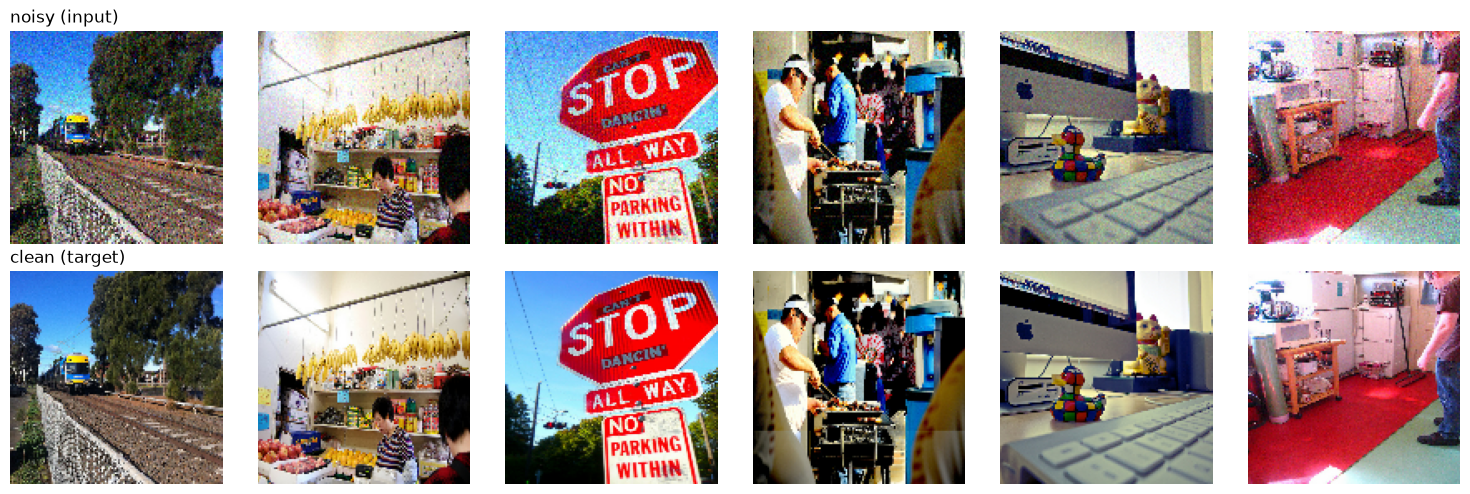

In [6]:
noisy_b, clean_b = next(iter(val_ds))
fig, axes = plt.subplots(2, 6, figsize=(15, 5))
for i in range(6):
    axes[0, i].imshow(noisy_b[i]); axes[0, i].axis("off")
    axes[1, i].imshow(clean_b[i]); axes[1, i].axis("off")
axes[0, 0].set_title("noisy (input)", loc="left"); axes[1, 0].set_title("clean (target)", loc="left")
plt.tight_layout()

## 4. Architecture of the convolutional autoencoder

The architecture of the workshop *Autoencodeur et traitement d'image*, adapted to colour images:

```
Input 128×128×3
 encoder : Conv2D 32 → MaxPooling 2×2     128 → 64
           Conv2D 32 → MaxPooling 2×2      64 → 32        bottleneck 32×32×32
 decoder : Conv2D 32 → UpSampling 2×2      32 → 64
           Conv2D 32 → UpSampling 2×2      64 → 128
           Conv2D 3, sigmoid                            → 128×128×3
```

- **The bottleneck is what denoises.** Noise is random, so it does not compress: there is no room to keep it. Reconstructing a plausible image is cheaper than reproducing the grain.
- **UpSampling mirrors MaxPooling**, so the output has exactly the shape of the input — unlike the classifier, which collapses everything into one number.
- **sigmoid on the last layer**, with **3 channels**: the output must be pixels in [0, 1], like the normalised input. This is the one real difference from the MNIST workshop, which used a single channel.

**Loss: `mse`** rather than the workshop's `binary_crossentropy`. On MNIST, pixels are nearly binary, which makes cross-entropy natural; our photographs are continuous, denoising is a regression on pixel values, and the mean squared error is also what **PSNR** is computed from — so the training objective and the reported metric agree.

In [7]:
def build_denoiser(name="denoiser", size=IMG_SIZE):
    # size=None gives a model that accepts any image size (the network is fully convolutional)
    model = Sequential([
        layers.Input(shape=(size, size, 3)),
        layers.Conv2D(32, 3, activation="relu", padding="same"),
        layers.MaxPooling2D(padding="same"),
        layers.Conv2D(32, 3, activation="relu", padding="same"),
        layers.MaxPooling2D(padding="same", name="bottleneck"),
        layers.Conv2D(32, 3, activation="relu", padding="same"),
        layers.UpSampling2D(),
        layers.Conv2D(32, 3, activation="relu", padding="same"),
        layers.UpSampling2D(),
        layers.Conv2D(3, 3, activation="sigmoid", padding="same"),
    ], name=name)
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse", metrics=["mae"])
    return model

denoiser = build_denoiser()
denoiser.summary()

Model: "denoiser"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bottleneck (MaxPooling2D)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 128, 128, 3)    │           867 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,507 (115.26 KB)

 Trainable params: 29,507 (115.26 KB)

 Non-trainable params: 0 (0.00 B)

## 5. Training
Early stopping on the validation loss, restoring the best epoch — the same correction as in Livrable 1.

Epoch 1/20


C:\my\Claude\cesi-data-science\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


C:\my\Claude\cesi-data-science\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


160/160 - 41s - 253ms/step - loss: 0.0223 - mae: 0.1055 - val_loss: 0.0123 - val_mae: 0.0739


Epoch 2/20


...

160/160 - 36s - 225ms/step - loss: 0.0069 - mae: 0.0534 - val_loss: 0.0068 - val_mae: 0.0528


Epoch 20/20


160/160 - 36s - 223ms/step - loss: 0.0068 - mae: 0.0531 - val_loss: 0.0066 - val_mae: 0.0518


Restoring model weights from the end of the best epoch: 20.


,loss,mae,val_loss,val_mae
1,0.02234,0.10546,0.01229,0.07390
2,0.01119,0.07018,0.01032,0.06665
3,0.01005,0.06601,0.00954,0.06358
4,0.00934,0.06282,0.00902,0.06114
5,0.00906,0.06186,0.00888,0.06113
6,0.00868,0.05995,0.00850,0.05935
7,0.00851,0.05945,0.00828,0.05824
8,0.00827,0.05829,0.00809,0.05745
9,0.00815,0.05800,0.00797,0.05691
10,0.00798,0.05725,0.00805,0.05814


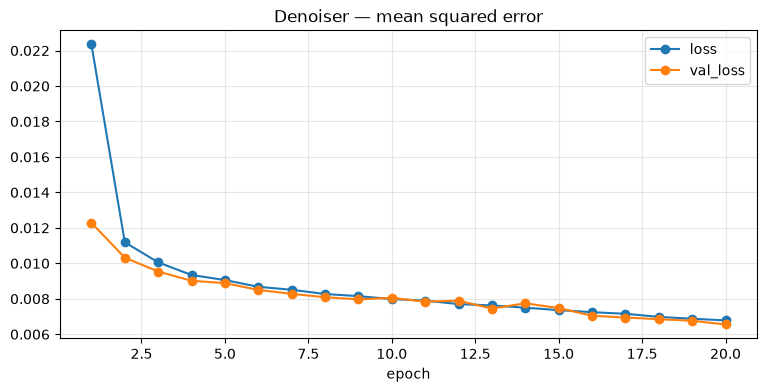

In [8]:
history = denoiser.fit(
    train_ds, validation_data=val_ds, epochs=MAX_EPOCHS,
    callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE,
                                             restore_best_weights=True, verbose=1)],
    verbose=2)

h = pd.DataFrame(history.history); h.index += 1
h[["loss", "val_loss"]].plot(marker="o", figsize=(9, 4), title="Denoiser — mean squared error")
plt.xlabel("epoch"); plt.grid(alpha=0.3)
h.round(5)

## 6. Evaluation on known pairs
Here we **do** have the ground truth, because we created the noise. The standard measure is the **PSNR** (peak signal-to-noise ratio), in decibels:

`PSNR = 10 · log10(1 / MSE)` for pixels in [0, 1]

Higher is better; +3 dB means the squared error was halved. The honest comparison is **noisy vs clean** against **denoised vs clean**: the difference is what the model actually bought.

In [9]:
def psnr(a, b):
    return float(tf.reduce_mean(tf.image.psnr(a, b, max_val=1.0)))

rows = []
for noisy_b, clean_b in val_ds.take(10):
    out = denoiser.predict(noisy_b, verbose=0)
    rows.append({"noisy vs clean": psnr(noisy_b, clean_b),
                 "denoised vs clean": psnr(tf.convert_to_tensor(out), clean_b)})
res = pd.DataFrame(rows).mean()
res["gain (dB)"] = res["denoised vs clean"] - res["noisy vs clean"]
res.round(2).to_frame("PSNR (dB)")

,PSNR (dB)
noisy vs clean,25.57
denoised vs clean,22.65
gain (dB),-2.92


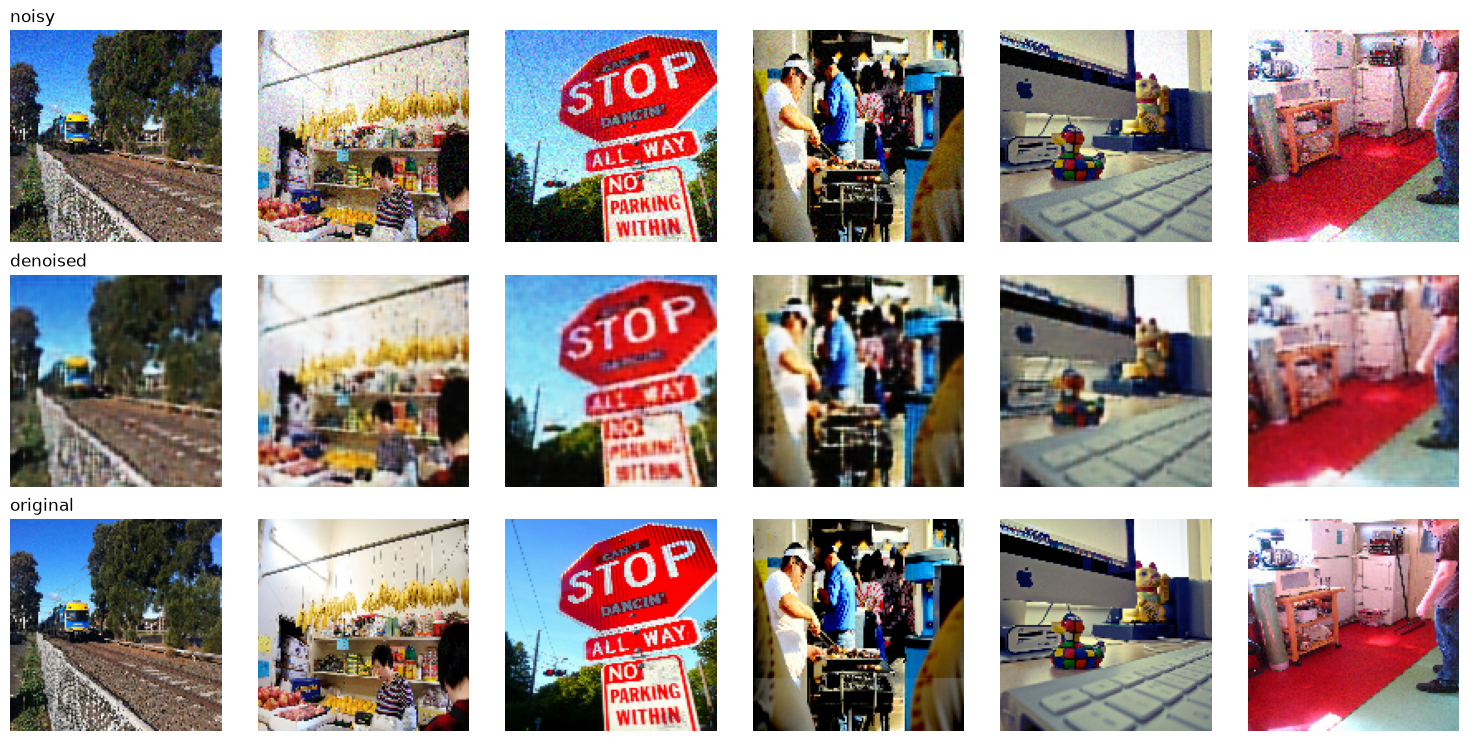

In [10]:
noisy_b, clean_b = next(iter(val_ds))
out = denoiser.predict(noisy_b, verbose=0)
fig, axes = plt.subplots(3, 6, figsize=(15, 7.5))
for i in range(6):
    axes[0, i].imshow(noisy_b[i]); axes[1, i].imshow(out[i]); axes[2, i].imshow(clean_b[i])
    for r in range(3):
        axes[r, i].axis("off")
for r, lab in enumerate(["noisy", "denoised", "original"]):
    axes[r, 0].set_title(lab, loc="left")
plt.tight_layout()

## 6b. Model B — residual learning and skip connections

Model A loses PSNR: the reconstruction is blurrier than the noise is strong. The diagnosis is structural, so the fix is too.

**Residual learning.** Instead of rebuilding the image, the network predicts **the noise**, and we subtract it:

```
output = input − predicted_noise
```

The detail of the original image passes through untouched; only the correction is learned. If the model predicts nothing at all, the output equals the input — so it starts from "do no harm" rather than from "rebuild everything from a bottleneck". This is how DnCNN works.

**Skip connections (U-Net).** The encoder's feature maps are concatenated into the decoder at the same resolution, so fine detail bypasses the bottleneck instead of having to survive it.

Everything else is identical — same data, same pairs, same loss, same early stopping — so the comparison measures these two ideas and nothing else.

In [11]:
def build_residual_denoiser(name="denoiser_residual", size=IMG_SIZE):
    inp = layers.Input(shape=(size, size, 3))      # size=None: any image size

    c1 = layers.Conv2D(32, 3, activation="relu", padding="same")(inp)   # 128
    p1 = layers.MaxPooling2D()(c1)                                      # 64
    c2 = layers.Conv2D(32, 3, activation="relu", padding="same")(p1)
    p2 = layers.MaxPooling2D()(c2)                                      # 32, bottleneck

    d1 = layers.Conv2D(32, 3, activation="relu", padding="same")(p2)
    u1 = layers.UpSampling2D()(d1)                                      # 64
    m1 = layers.Concatenate()([u1, c2])                                 # skip connection
    d2 = layers.Conv2D(32, 3, activation="relu", padding="same")(m1)
    u2 = layers.UpSampling2D()(d2)                                      # 128
    m2 = layers.Concatenate()([u2, c1])                                 # skip connection

    # No activation here: the predicted noise can be positive or negative
    noise = layers.Conv2D(3, 3, padding="same", name="predicted_noise")(m2)
    clean = layers.Subtract()([inp, noise])
    out = layers.ReLU(max_value=1.0)(clean)        # keeps the result inside [0, 1]

    model = keras.Model(inp, out, name=name)
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse", metrics=["mae"])
    return model

model_b = build_residual_denoiser()
model_b.summary()

Model: "denoiser_residual"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 128, 128,  │        896 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 64, 64,    │          0 │ conv2d_5[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 64, 64,    │      9,248 │ max_pooling2d_1[… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 32, 32,    │          0 │ conv2d_6[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 32, 32,    │      9,248 │ max_pooling2d_2[… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_2     │ (None, 64, 64,    │          0 │ conv2d_7[0][0]    │
│ (UpSampling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 64, 64,    │          0 │ up_sampling2d_2[… │
│ (Concatenate)       │ 64)               │            │ conv2d_6[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 64, 64,    │     18,464 │ concatenate[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_3     │ (None, 128, 128,  │          0 │ conv2d_8[0][0]    │
│ (UpSampling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 128, 128,  │          0 │ up_sampling2d_3[… │
│ (Concatenate)       │ 64)               │            │ conv2d_5[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ predicted_noise     │ (None, 128, 128,  │      1,731 │ concatenate_1[0]… │
│ (Conv2D)            │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ subtract (Subtract) │ (None, 128, 128,  │          0 │ input_layer_1[0]… │
│                     │ 3)                │            │ predicted_noise[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (None, 128, 128,  │          0 │ subtract[0][0]    │
│                     │ 3)                │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 39,587 (154.64 KB)

 Trainable params: 39,587 (154.64 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20


C:\my\Claude\cesi-data-science\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


C:\my\Claude\cesi-data-science\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


160/160 - 60s - 374ms/step - loss: 0.0036 - mae: 0.0441 - val_loss: 0.0021 - val_mae: 0.0341


Epoch 2/20


...

160/160 - 55s - 344ms/step - loss: 0.0013 - mae: 0.0259 - val_loss: 0.0013 - val_mae: 0.0261


Epoch 20/20


160/160 - 55s - 342ms/step - loss: 0.0013 - mae: 0.0258 - val_loss: 0.0013 - val_mae: 0.0258


Restoring model weights from the end of the best epoch: 20.


,loss,mae,val_loss,val_mae
1,0.00356,0.04412,0.00208,0.03406
2,0.00180,0.03150,0.00166,0.03010
3,0.00161,0.02958,0.00156,0.02903
4,0.00151,0.02858,0.00149,0.02825
5,0.00145,0.02791,0.00141,0.02742
6,0.00140,0.02730,0.00138,0.02708
7,0.00138,0.02707,0.00136,0.02682
8,0.00135,0.02679,0.00134,0.02666
9,0.00134,0.02669,0.00137,0.02711
10,0.00133,0.02657,0.00131,0.02636


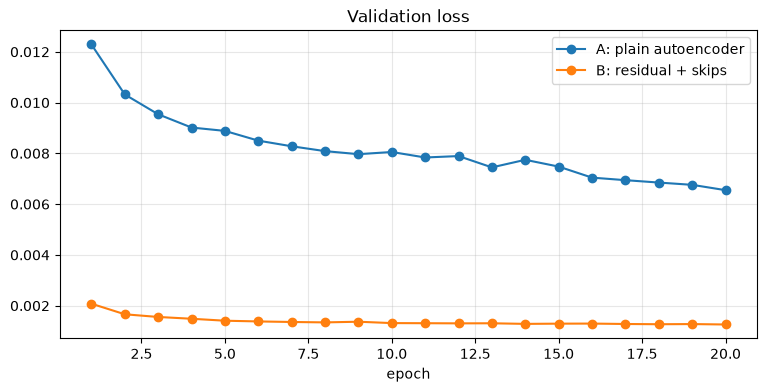

In [12]:
history_b = model_b.fit(
    train_ds, validation_data=val_ds, epochs=MAX_EPOCHS,
    callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE,
                                             restore_best_weights=True, verbose=1)],
    verbose=2)

hb = pd.DataFrame(history_b.history); hb.index += 1
ax = h[["val_loss"]].rename(columns={"val_loss": "A: plain autoencoder"}).plot(marker="o", figsize=(9, 4))
hb[["val_loss"]].rename(columns={"val_loss": "B: residual + skips"}).plot(ax=ax, marker="o")
ax.set_title("Validation loss"); ax.set_xlabel("epoch"); ax.grid(alpha=0.3)
hb.round(5)

In [13]:
rows = []
for noisy_b, clean_b in val_ds.take(10):
    a = denoiser.predict(noisy_b, verbose=0)
    b = model_b.predict(noisy_b, verbose=0)
    rows.append({"noisy": psnr(noisy_b, clean_b),
                 "A: plain": psnr(tf.convert_to_tensor(a), clean_b),
                 "B: residual + skips": psnr(tf.convert_to_tensor(b), clean_b)})
comp = pd.DataFrame(rows).mean()
comp["gain A"] = comp["A: plain"] - comp["noisy"]
comp["gain B"] = comp["B: residual + skips"] - comp["noisy"]
comp.round(2).to_frame("PSNR (dB)")

,PSNR (dB)
noisy,25.57
A: plain,22.65
B: residual + skips,29.75
gain A,-2.93
gain B,4.18


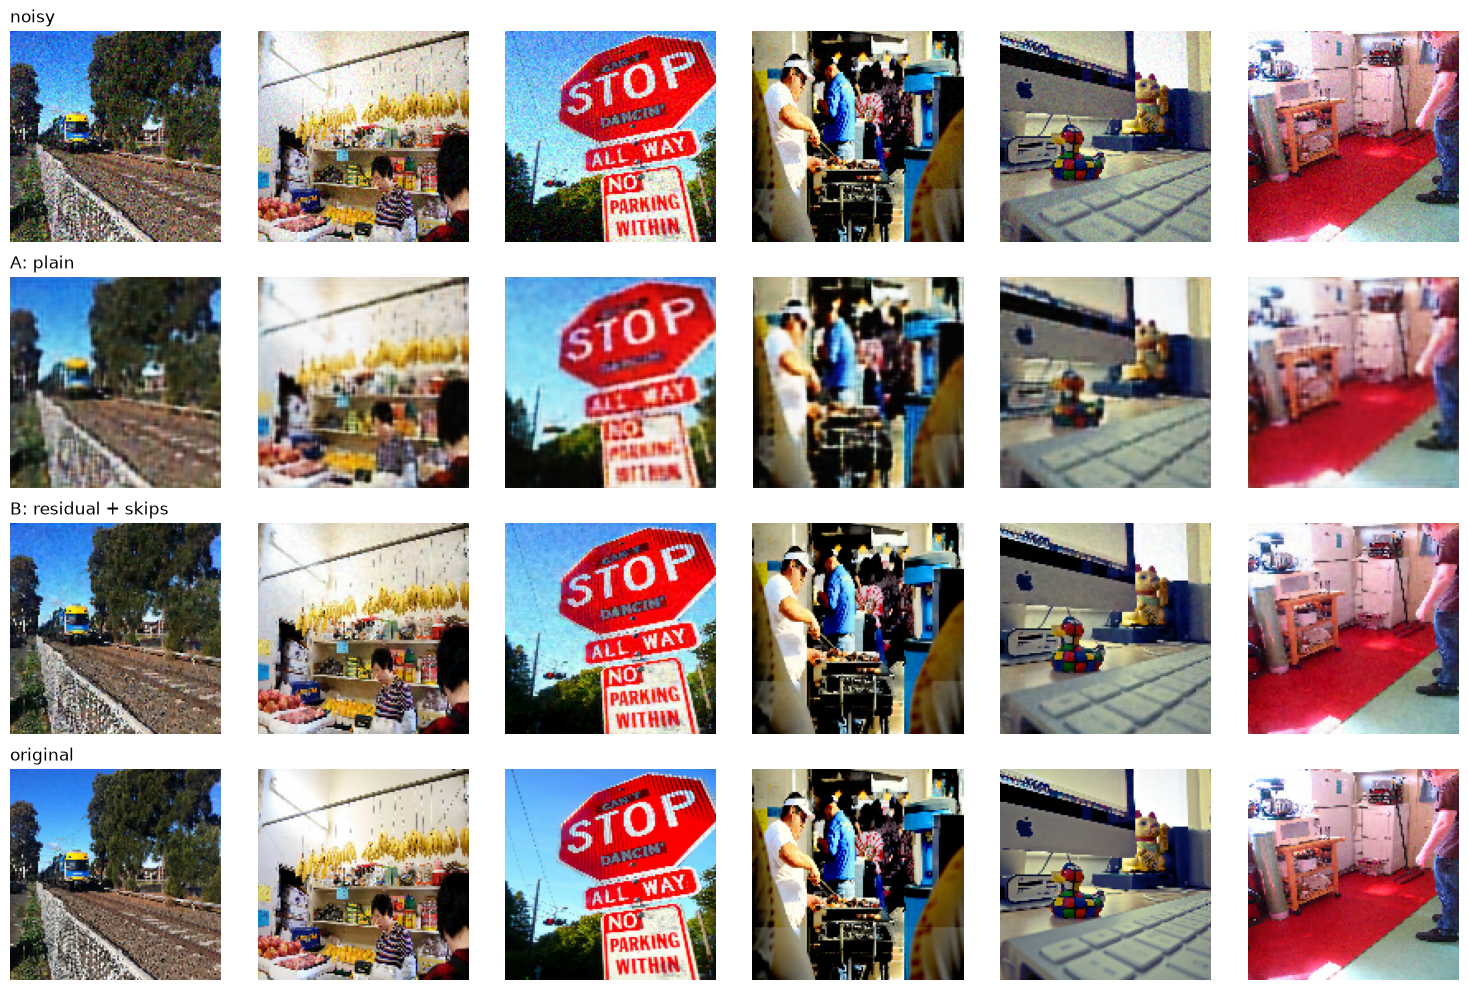

In [14]:
noisy_b, clean_b = next(iter(val_ds))
a = denoiser.predict(noisy_b, verbose=0)
b = model_b.predict(noisy_b, verbose=0)
fig, axes = plt.subplots(4, 6, figsize=(15, 10))
for i in range(6):
    for r, img in enumerate([noisy_b[i], a[i], b[i], clean_b[i]]):
        axes[r, i].imshow(img); axes[r, i].axis("off")
for r, lab in enumerate(["noisy", "A: plain", "B: residual + skips", "original"]):
    axes[r, 0].set_title(lab, loc="left")
plt.tight_layout()

In [15]:
# The rest of the notebook uses whichever model won on the validation pairs.
best_denoiser = model_b if comp["gain B"] > comp["gain A"] else denoiser
print("kept:", best_denoiser.name, "| PSNR gain", round(max(comp["gain A"], comp["gain B"]), 2), "dB")

kept: denoiser_residual | PSNR gain 4.18 dB


*Comment on the table: did residual learning turn the gain positive, and by how much? Say also what it costs — the parameter count and the training time are in the summaries above.*

## 7. Application to TouNum's real images
The real test. Here there is **no ground truth**, so PSNR is impossible and the evaluation has to be indirect:

1. **Visual**: is the grain gone, and is the detail still there?
2. **The sigma estimator of section 2**, applied before and after.
3. **The Livrable 1 classifier**: if denoising really restores the appearance of a photograph, its confidence `p(photo)` should rise. This uses one deliverable to measure the other.

In [16]:
# The denoiser was trained at 128x128 but is fully convolutional, so the same
# weights run at the classifier's 256x256: we rebuild it with a free input size
# and copy the trained weights. The real images are then cleaned at the exact
# resolution the Livrable 1 classifier sees, with no extra resizing in between.
BUILDERS = {"denoiser": build_denoiser, "denoiser_residual": build_residual_denoiser}
apply_denoiser = BUILDERS[best_denoiser.name](size=None)
apply_denoiser.set_weights(best_denoiser.get_weights())

real = real_cls                                   # (148, 256, 256, 3), padded, in [0, 1]
real_out = apply_denoiser.predict(real, batch_size=8, verbose=0)

before = np.array([estimate_sigma(im) for im in real[:40]])
after = np.array([estimate_sigma(im) for im in real_out[:40]])
print(f"estimated sigma  before {before.mean():.3f}   after {after.mean():.3f}")

p_after = p_photo_of(real_out)
print(f"p(photo) mean    before {p_photo.mean():.3f}   after {p_after.mean():.3f}")
print(f"kept as photos   before {(p_photo >= THRESHOLD).sum()}   after {(p_after >= THRESHOLD).sum()}  of {len(noisy_paths)}")

estimated sigma  before 0.005   after 0.001


p(photo) mean    before 0.669   after 0.731
kept as photos   before 102   after 115  of 148


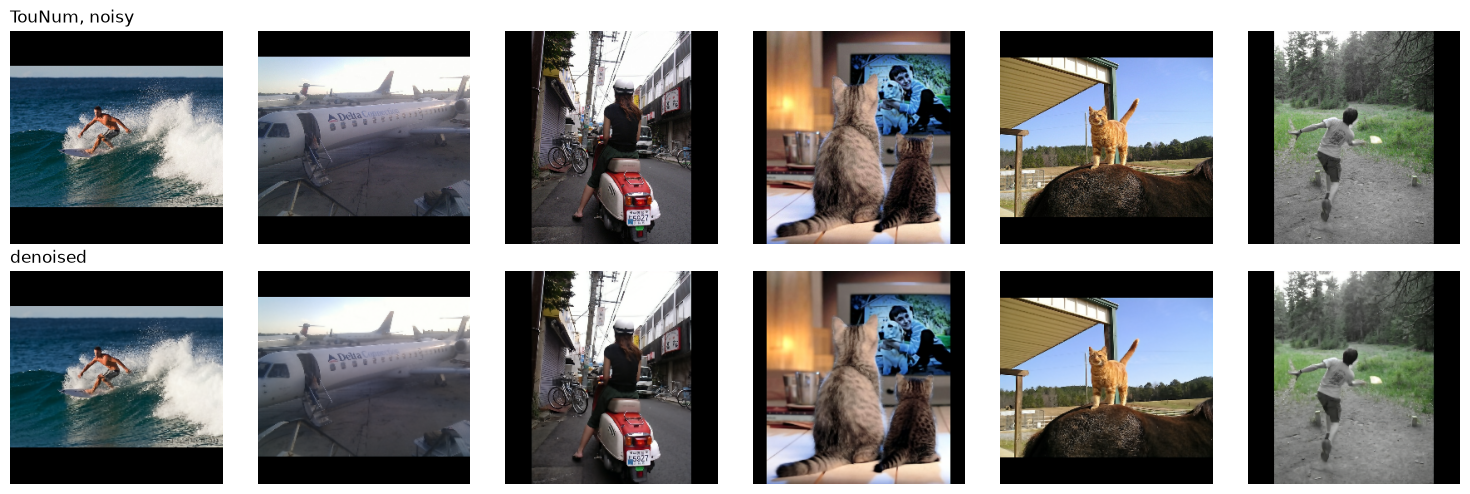

In [17]:
fig, axes = plt.subplots(2, 6, figsize=(15, 5))
for i in range(6):
    axes[0, i].imshow(real[i]); axes[0, i].axis("off")
    axes[1, i].imshow(real_out[i]); axes[1, i].axis("off")
axes[0, 0].set_title("TouNum, noisy", loc="left"); axes[1, 0].set_title("denoised", loc="left")
plt.tight_layout()

*Comment here on the three measurements. Watch in particular for the gap between the synthetic case and the real one: our noise is Gaussian and uniform, while a real scan may carry compression artefacts, blur or coloured noise. A model trained on one kind of noise has no reason to excel on another — say so rather than hide it.*

## 8. The autoencoder as a feature extractor
The workshop *Autoencodeur et classification binaire* uses the encoder differently: not to rebuild an image, but to **describe** it compactly, and then classify from that description.

We reuse the encoder just trained — its bottleneck is 32×32×32 — pool it into 32 numbers per image, and train a simple classifier on those. The comparison with the CNN of Livrable 1 is the point: **how much is lost by replacing a supervised network with 32 unsupervised features?**

In [18]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

# Keras 3 does not expose .input on a Sequential model, so the encoder is built
# by replaying the trained layers up to the bottleneck (same weights, no copy).
enc_in = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = enc_in
for layer in denoiser.layers:
    x = layer(x)
    if layer.name == "bottleneck":
        break
encoder = keras.Model(enc_in, layers.GlobalAveragePooling2D()(x), name="encoder")
print("encoder output:", encoder.output_shape)

SOURCES = ["Photo", "Painting", "Schematics", "Sketch", "Text"]
rows = []
for src in SOURCES:
    for p in list_images(src)[:1200]:
        rows.append({"path": str(p), "source": src, "is_photo": int(src == "Photo")})
sub = pd.DataFrame(rows).sample(frac=1, random_state=SEED).reset_index(drop=True)
print(len(sub), "images encoded")

ds = (tf.data.Dataset.from_tensor_slices(sub.path.values)
      .map(load_clean, num_parallel_calls=tf.data.AUTOTUNE).batch(64).prefetch(tf.data.AUTOTUNE))
Z = encoder.predict(ds, verbose=0)
y = sub.is_photo.values
print("features:", Z.shape)

cut = int(0.8 * len(Z))
clf = LogisticRegression(max_iter=2000).fit(Z[:cut], y[:cut])
print(classification_report(y[cut:], clf.predict(Z[cut:]), target_names=["other", "photo"], digits=4))

encoder output: (None, 32)


6000 images encoded


features: (6000, 32)
              precision    recall  f1-score   support

       other     0.8521    0.9051    0.8778       980
       photo     0.4151    0.3000    0.3483       220

    accuracy                         0.7942      1200
   macro avg     0.6336    0.6026    0.6130      1200
weighted avg     0.7720    0.7942    0.7807      1200



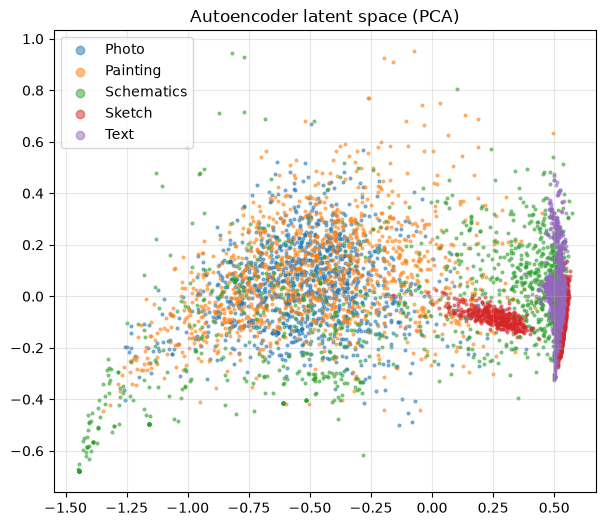

In [19]:
# What do the 32 features see? PCA of the latent space, coloured by source.
from sklearn.decomposition import PCA

P = PCA(n_components=2).fit_transform(Z)
plt.figure(figsize=(7, 6))
for src in SOURCES:
    m = sub.source.values == src
    plt.scatter(P[m, 0], P[m, 1], s=4, alpha=0.5, label=src)
plt.legend(markerscale=3); plt.title("Autoencoder latent space (PCA)"); plt.grid(alpha=0.3)

*Compare the F1 on the photo class with that of Livrable 1, and say why the difference exists. Two reasons to weigh: these 32 features were learned to **reconstruct**, not to **separate** — nothing told them that "photo versus painting" matters; and pooling the bottleneck throws away the spatial layout. A supervised CNN optimises exactly the quantity being measured, so it should win; the question is by how much, and at what cost in labels.*

## 9. Analysis and improvements

| Lever | Expected effect | Status |
|---|---|---|
| **Noise drawn per image and per epoch** | The model handles a range of levels, not one | Applied |
| **Early stopping** | Keeps the best epoch | Applied |
| **Larger images** (256 px) | Fine detail survives the reconstruction | Not done: CPU |
| **Skip connections (U-Net)** | Carry detail from encoder to decoder; the usual cure for the blur of a plain autoencoder | The first thing to try |
| **Wider bottleneck** | Less blur, but less denoising — the trade-off to measure | To try |
| **Perceptual loss** | MSE favours blurry images, since blurring is the safest way to reduce squared error | Advanced |
| **Real noise instead of Gaussian** | Scans also carry JPEG artefacts and blur | Would need clean/noisy pairs from TouNum |

**For TouNum's pipeline**, the honest conclusion to present: the model removes the kind of noise we modelled, measured by PSNR on known pairs, and the visual result on the real batch is *(fill in)*. To go further we would ask the client for a sample of images **scanned twice**, once in fast mode and once in quality mode — that would give real pairs and remove every assumption we had to make here.

In [20]:
Path("models").mkdir(exist_ok=True)
best_denoiser.save("models/denoiser_rgb.keras")
print("saved models/denoiser_rgb.keras ->", best_denoiser.name)

saved models/denoiser_rgb.keras -> denoiser_residual
